In [ ]:
!pip install transformers torchaudio librosa scikit-learn tqdm

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!cp /content/drive/MyDrive/IEMOCAPdataset/IEMOCAP_full_release_withoutVideos.tar.gz /content/

In [ ]:
!tar -xzvf IEMOCAP_full_release_withoutVideos.tar.gz

Streaming output truncated to the last 5000 lines.
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M030.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M021.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F007.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F003.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M033.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F013.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_F022.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M012.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses05F_script03_1/Ses05F_script03_1_M016.txt
IEMOCAP_full_release/Session5/sentences/MOCAP_rotated/Ses0

In [ ]:
import os

dataset_path = "/content/IEMOCAP_full_release"

print(os.listdir(dataset_path))

['README.txt', 'Session3', 'Session1', 'README.txt~', 'Documentation', 'Session2', 'Session5', 'Session4']


In [ ]:
!pip install -U transformers accelerate librosa soundfile scikit-learn -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 80.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 86.9 MB/s eta 0:00:00


Using Device: cuda

 Total Samples: 5621


Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]


 Extracting WavLM Features...



100%|██████████| 5621/5621 [02:47<00:00, 33.49it/s]



 Feature Shape: (5621, 768)

 Classes: ['ang' 'hap' 'neu' 'sad']

 PCA Output Shape: (4496, 50)

 Class Weights: tensor([1.2643, 0.8496, 0.8006, 1.2773], device='cuda:0')

 Training Started...

Epoch 1/15 Loss: 1.1284
Epoch 2/15 Loss: 1.0294
Epoch 3/15 Loss: 0.9768
Epoch 4/15 Loss: 0.9445
Epoch 5/15 Loss: 0.9382
Epoch 6/15 Loss: 0.9159
Epoch 7/15 Loss: 0.8883
Epoch 8/15 Loss: 0.8914
Epoch 9/15 Loss: 0.8742
Epoch 10/15 Loss: 0.8594
Epoch 11/15 Loss: 0.8495
Epoch 12/15 Loss: 0.8268
Epoch 13/15 Loss: 0.8348
Epoch 14/15 Loss: 0.8221
Epoch 15/15 Loss: 0.8110

 Accuracy: 0.6231111111111111

 Classification Report:

              precision    recall  f1-score   support

         ang       0.70      0.74      0.72       223
         hap       0.66      0.55      0.60       331
         neu       0.60      0.55      0.57       351
         sad       0.55      0.73      0.63       220

    accuracy                           0.62      1125
   macro avg       0.63      0.64      0.63      1125
we

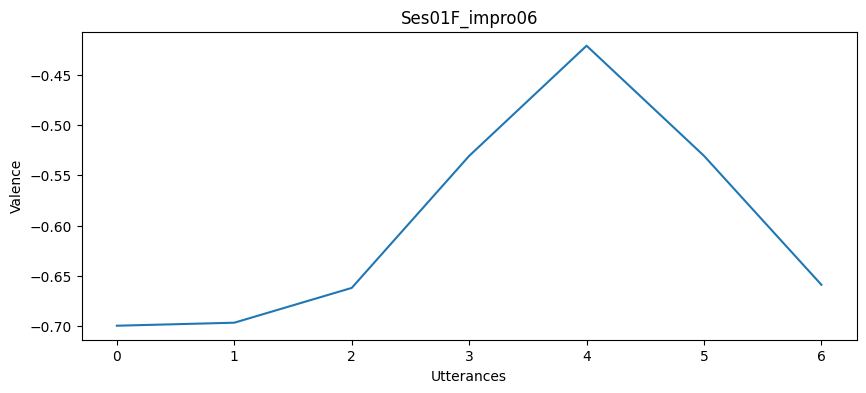


 Positive Emotion Trend


In [ ]:
# AUDIO-ONLY EMOTION RECOGNITION (WavLM-base)


!pip install -U transformers librosa soundfile scikit-learn -q

# IMPORTS
import os
import re
import glob
import librosa
import numpy as np
import pandas as pd
import soundfile as sf

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from transformers import (
    Wav2Vec2FeatureExtractor,
    WavLMModel
)

# DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device:", device)

# DATASET PATH
DATA_PATH = "/content/IEMOCAP_full_release"

# VALID EMOTIONS
valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths = []
labels = []

# LOAD DATA
for session in range(1, 6):

    session_path = os.path.join(
        DATA_PATH,
        f"Session{session}"
    )

    wav_files = glob.glob(
        os.path.join(session_path, "**/*.wav"),
        recursive=True
    )

    for wav_file in wav_files:

        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        # Annotation filename
        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(
            session_path,
            "dialog",
            "EmoEvaluation",
            ann_name
        )

        if not os.path.exists(ann_path):
            continue

                # EMOTION LABEL
        emotion = None

        with open(ann_path, "r") as f:

            for line in f:

                if file_id in line:

                    try:
                        emotion = line.strip().split()[4]

                    except:
                        continue

                    break

        # Skip unwanted emotions
        if emotion not in valid_emotions:
            continue

        # Merge excited into happy
        if emotion == "exc":
            emotion = "hap"

        wav_paths.append(wav_file)
        labels.append(emotion)

print("\n Total Samples:", len(wav_paths))

# LOAD WavLM MODEL
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
    "microsoft/wavlm-base"
)

wavlm_model = WavLMModel.from_pretrained(
    "microsoft/wavlm-base"
).to(device)

wavlm_model.eval()

# AUDIO FEATURE EXTRACTION
MAX_AUDIO_LENGTH = 80000

def extract_wavlm_embedding(file_path):

    signal, sr = sf.read(file_path)

    # Stereo → Mono
    if len(signal.shape) > 1:
        signal = np.mean(signal, axis=1)

    # Resample
    if sr != 16000:
        signal = librosa.resample(
            signal,
            orig_sr=sr,
            target_sr=16000
        )

    # Limit audio length
    signal = signal[:MAX_AUDIO_LENGTH]

    # Normalize audio
    signal = signal / (np.max(np.abs(signal)) + 1e-9)

    # Feature extractor
    inputs = feature_extractor(
        signal,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    input_values = inputs.input_values.to(device)

    with torch.no_grad():

        outputs = wavlm_model(input_values)

    # Mean pooling
    embedding = outputs.last_hidden_state.mean(dim=1)

    return embedding.cpu().numpy().flatten()

# FEATURE EXTRACTION
X = []
y = []
paths = []

print("\n Extracting WavLM Features...\n")

for i in tqdm(range(len(wav_paths))):

    try:

        audio_feat = extract_wavlm_embedding(
            wav_paths[i]
        )

        # Reduce RAM usage
        X.append(audio_feat.astype(np.float32))

        y.append(labels[i])
        paths.append(wav_paths[i])

    except Exception as e:

        print(f"Skipped File: {wav_paths[i]}")
        print("Reason:", e)

X = np.array(X, dtype=np.float32)
y = np.array(y)

torch.cuda.empty_cache()

print("\n Feature Shape:", X.shape)

# LABEL ENCODING
le = LabelEncoder()

y = le.fit_transform(y)

print("\n Classes:", le.classes_)

# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X,
    y,
    paths,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# NORMALIZATION
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PCA
pca = PCA(n_components=50)

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print("\n PCA Output Shape:", X_train.shape)

# CLASS WEIGHTS (IMBALANCE HANDLING)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("\n Class Weights:", class_weights)

# MODEL
class EmotionMLP(nn.Module):

    def __init__(self, input_size, num_classes):

        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)

        )

    def forward(self, x):

        return self.net(x)

# INITIALIZE MODEL
model = EmotionMLP(
    X_train.shape[1],
    len(np.unique(y))
).to(device)

# DATALOADERS
train_loader = torch.utils.data.DataLoader(

    torch.utils.data.TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train)
    ),

    batch_size=8,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(

    torch.utils.data.TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test)
    ),

    batch_size=8,
    shuffle=False
)

# LOSS FUNCTION
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

# OPTIMIZER
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=5e-4
)

# TRAINING
EPOCHS = 15

print("\n Training Started...\n")

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        preds = model(xb)

        loss = criterion(preds, yb)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    print(
        f"Epoch {epoch+1}/{EPOCHS} "
        f"Loss: {avg_loss:.4f}"
    )

# EVALUATION
model.eval()

all_preds = []

with torch.no_grad():

    for xb, _ in test_loader:

        xb = xb.to(device)

        preds = model(xb)

        preds = torch.argmax(
            preds,
            dim=1
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

# RESULTS
print(
    "\n Accuracy:",
    accuracy_score(y_test, all_preds)
)

print("\n Classification Report:\n")

print(
    classification_report(
        y_test,
        all_preds,
        target_names=le.classes_
    )
)

pred_labels = le.inverse_transform(all_preds)

# CONVERSATION GROUPING
records = []

for idx, (path, pred) in enumerate(
    zip(paths_test, pred_labels)
):

    filename = os.path.basename(path).replace(".wav", "")

    parts = filename.split("_")

    conv_id = "_".join(parts[:2])

    match = re.search(r'[MF](\d+)', filename)

    utt_id = int(match.group(1)) if match else idx

    records.append({

        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred

    })

df = pd.DataFrame(records)

df = df.sort_values(
    by=["conversation_id", "utterance_id"]
)

# EMOTION TREND ANALYSIS
VAD_MAP = {

    "hap": (0.8, 0.7, 0.6),
    "sad": (-0.7, 0.3, 0.4),
    "ang": (-0.6, 0.8, 0.7),
    "neu": (0.0, 0.5, 0.5)

}

os.makedirs("plots", exist_ok=True)

print("\n Generating Emotion Trend Plots...\n")

for cid, grp in df.groupby("conversation_id"):

    emotions = grp["emotion_label"].tolist()

    vad = np.array([
        VAD_MAP[e]
        for e in emotions
    ])

    val = gaussian_filter1d(vad[:, 0], 1)
    aro = gaussian_filter1d(vad[:, 1], 1)
    dom = gaussian_filter1d(vad[:, 2], 1)

    plt.figure(figsize=(10, 4))

    plt.plot(val, label="Valence")
    plt.plot(aro, label="Arousal")
    plt.plot(dom, label="Dominance")

    plt.title(cid)

    plt.legend()

    plt.savefig(f"plots/{cid}.png")

    plt.close()

print("\n All plots saved inside 'plots/' folder")

# USER QUERY
print("\n Available Conversation IDs:\n")

print(df["conversation_id"].unique()[:10])

cid = input("\nEnter conversation ID: ")

subset = df[
    df["conversation_id"] == cid
]

if len(subset) > 0:

    emotions = subset["emotion_label"].tolist()

    vad = np.array([
        VAD_MAP[e]
        for e in emotions
    ])

    val = gaussian_filter1d(vad[:, 0], 1)

    plt.figure(figsize=(10, 4))

    plt.plot(val)

    plt.title(cid)

    plt.xlabel("Utterances")
    plt.ylabel("Valence")

    plt.show()

    trend = val[-1] - val[0]

    if trend > 0:
        print("\n Positive Emotion Trend")

    elif trend < 0:
        print("\n Negative Emotion Trend")

    else:
        print("\n Stable Emotion Trend")

else:
    print("\n Conversation ID not found")

In [ ]:
import shutil

shutil.make_archive(
    "/content/emotion_trend_plots",
    'zip',
    "/content/plots"
)

print("ZIP file created successfully")

ZIP file created successfully


Using device: cuda


Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

WavLM-large loaded
Total samples: 5621
Loading cache: train_cache.pkl
Loading cache: test_cache.pkl


100%|██████████| 2248/2248 [00:44<00:00, 49.99it/s]


Epoch 1/5, Loss: 0.4602


100%|██████████| 2248/2248 [00:27<00:00, 81.65it/s]


... (5 outputs left out)

100%|██████████| 2248/2248 [00:24<00:00, 93.15it/s]


Epoch 5/5, Loss: 0.1417


100%|██████████| 563/563 [00:01<00:00, 294.98it/s]



Accuracy: 0.6391111111111111
              precision    recall  f1-score   support

         ang       0.76      0.76      0.76       223
         hap       0.60      0.77      0.68       331
         neu       0.68      0.36      0.47       351
         sad       0.57      0.76      0.65       220

    accuracy                           0.64      1125
   macro avg       0.65      0.66      0.64      1125
weighted avg       0.65      0.64      0.62      1125

Plots saved in plots/ folder

Available Conversation IDs:
['Ses01F_impro01' 'Ses01F_impro02' 'Ses01F_impro03' 'Ses01F_impro04'
 'Ses01F_impro05' 'Ses01F_impro06' 'Ses01F_impro07' 'Ses01F_script01'
 'Ses01F_script02' 'Ses01F_script03']

Enter conversation ID: Ses03M_impro04


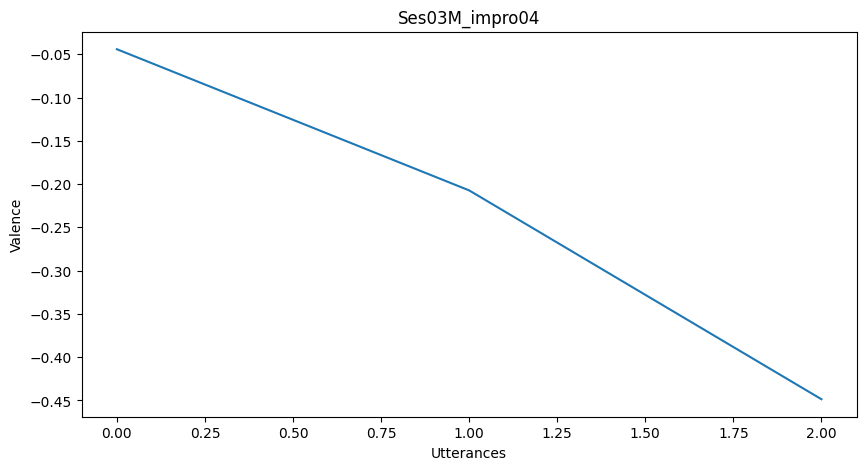

Negative Trend


In [ ]:
# wavlm-large +Transformers
import os
import re
import glob
import pickle
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from transformers import Wav2Vec2FeatureExtractor, WavLMModel

# DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# LOAD WAVLM LARGE
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
    "microsoft/wavlm-large"
)

wavlm = WavLMModel.from_pretrained(
    "microsoft/wavlm-large"
).to(device)

wavlm.eval()

print("WavLM-large loaded")

# DATA PATH
DATA_PATH = "/content/IEMOCAP_full_release"

valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths = []
labels = []

# LOAD DATA
for session in range(1, 6):

    session_path = os.path.join(DATA_PATH, f"Session{session}")

    wav_files = glob.glob(
        os.path.join(session_path, "**/*.wav"),
        recursive=True
    )

    for wav_file in wav_files:

        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(
            session_path,
            "dialog",
            "EmoEvaluation",
            ann_name
        )

        if not os.path.exists(ann_path):
            continue

        emotion = None

        with open(ann_path, "r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                if file_id in line:
                    split_line = line.strip().split()
                    if len(split_line) >= 5:
                        emotion = split_line[4]
                    break

        if emotion not in valid_emotions:
            continue

        if emotion == "exc":
            emotion = "hap"

        wav_paths.append(wav_file)
        labels.append(emotion)

print("Total samples:", len(wav_paths))

# LABEL ENCODING
le = LabelEncoder()
y = le.fit_transform(labels)

# SPLIT
paths_train, paths_test, y_train, y_test = train_test_split(
    wav_paths,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# FEATURE EXTRACTION
def extract_wavlm_features(file_path, max_audio_len=4):

    signal, sr = librosa.load(
        file_path,
        sr=16000,
        duration=max_audio_len
    )

    inputs = feature_extractor(
        signal,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    input_values = inputs.input_values.to(device)

    with torch.no_grad():
        outputs = wavlm(input_values)

    hidden = outputs.last_hidden_state.squeeze(0)

    # sequence downsampling
    hidden = hidden[::6]

    return hidden.cpu()

# CACHE FEATURES
def cache_features(paths, cache_name):

    if os.path.exists(cache_name):
        print(f"Loading cache: {cache_name}")
        with open(cache_name, "rb") as f:
            return pickle.load(f)

    feats = []

    for p in tqdm(paths):
        feats.append(extract_wavlm_features(p))

    with open(cache_name, "wb") as f:
        pickle.dump(feats, f)

    return feats

train_features = cache_features(paths_train, "train_cache.pkl")
test_features = cache_features(paths_test, "test_cache.pkl")

# DATASET
class EmotionDataset(Dataset):

    def __init__(self, features, labels, paths):
        self.features = features
        self.labels = labels
        self.paths = paths

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return (
            self.features[idx],
            self.labels[idx],
            self.paths[idx]
        )

# COLLATE FUNCTION
def collate_fn(batch):

    features = [x[0] for x in batch]
    labels = [x[1] for x in batch]
    paths = [x[2] for x in batch]

    lengths = [f.shape[0] for f in features]
    max_len = max(lengths)

    padded = []
    masks = []

    for f in features:

        seq_len = f.shape[0]
        pad_len = max_len - seq_len

        if pad_len > 0:
            pad = torch.zeros(pad_len, f.shape[1])
            f = torch.cat([f, pad], dim=0)

        padded.append(f)

        mask = torch.cat([
            torch.zeros(seq_len),
            torch.ones(pad_len)
        ])

        masks.append(mask.bool())

    padded = torch.stack(padded)
    masks = torch.stack(masks)
    labels = torch.tensor(labels)

    return padded, masks, labels, paths

# IMBALANCE HANDLING
class_counts = np.bincount(y_train)
weights = 1. / class_counts
sample_weights = weights[y_train]

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# DATA LOADERS
train_dataset = EmotionDataset(
    train_features,
    y_train,
    paths_train
)

test_dataset = EmotionDataset(
    test_features,
    y_test,
    paths_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    sampler=sampler,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

# FOCAL LOSS
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(
            weight=alpha,
            reduction='none'
        )

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        pt = torch.exp(-ce_loss)
        loss = ((1 - pt) ** self.gamma) * ce_loss
        return loss.mean()

# CLASS WEIGHTS
cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw = torch.tensor(
    cw,
    dtype=torch.float32
).to(device)

# TRANSFORMER MODEL
class EmotionModel(nn.Module):
    def __init__(self):
        super().__init__()

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=1024,
            nhead=8,
            dim_feedforward=1024,
            dropout=0.2,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        self.attn = nn.Linear(1024, 1)

        self.fc = nn.Sequential(
            nn.Linear(1024, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 4)
        )

    def forward(self, x, mask):
        x = self.transformer(
            x,
            src_key_padding_mask=mask
        )

        weights = torch.softmax(
            self.attn(x),
            dim=1
        )

        x = torch.sum(x * weights, dim=1)

        return self.fc(x)

model = EmotionModel().to(device)

# LOSS + OPTIMIZER
criterion = FocalLoss(
    alpha=cw,
    gamma=2
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=2,
    factor=0.5
)

# EARLY STOPPING SETUP
best_loss = float("inf")
patience = 4
counter = 0

# TRAINING
EPOCHS = 5

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    optimizer.zero_grad()

    for i, (xb, mask, yb, _) in enumerate(tqdm(train_loader)):

        xb = xb.to(device)
        mask = mask.to(device)
        yb = yb.to(device)

        preds = model(xb, mask)

        loss = criterion(preds, yb)

        loss.backward()

        # gradient accumulation
        if (i + 1) % 4 == 0:
            optimizer.step()
            optimizer.zero_grad()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    scheduler.step(avg_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS}, "
        f"Loss: {avg_loss:.4f}"
    )

    # early stopping
    if avg_loss < best_loss:
        best_loss = avg_loss
        counter = 0
        torch.save(
            model.state_dict(),
            "best_model.pth"
        )
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping")
        break

# LOAD BEST MODEL
model.load_state_dict(
    torch.load("best_model.pth")
)

# EVALUATION
model.eval()

all_preds = []
all_true = []
all_paths = []

with torch.no_grad():

    for xb, mask, yb, paths in tqdm(test_loader):

        xb = xb.to(device)
        mask = mask.to(device)

        preds = model(xb, mask)
        preds = torch.argmax(preds, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_true.extend(yb.numpy())
        all_paths.extend(paths)

print("\nAccuracy:", accuracy_score(all_true, all_preds))

print(
    classification_report(
        all_true,
        all_preds,
        target_names=le.classes_
    )
)

pred_labels = le.inverse_transform(all_preds)

# CONVERSATION GROUPING
records = []

for idx, (path, pred) in enumerate(
    zip(all_paths, pred_labels)
):

    filename = os.path.basename(path).replace(".wav", "")
    parts = filename.split("_")

    conv_id = "_".join(parts[:2])

    match = re.search(r'[MF](\d+)', filename)

    if match:
        utt_id = int(match.group(1))
    else:
        utt_id = idx

    records.append({
        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records)

df = df.sort_values(
    by=["conversation_id", "utterance_id"]
)

# EMOTION TREND ANALYSIS
VAD_MAP = {
    "hap": (0.8, 0.7, 0.6),
    "sad": (-0.7, 0.3, 0.4),
    "ang": (-0.6, 0.8, 0.7),
    "neu": (0.0, 0.5, 0.5)
}

os.makedirs("plots", exist_ok=True)

for cid, grp in df.groupby("conversation_id"):

    emotions = grp["emotion_label"].tolist()

    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:, 0], 1)
    aro = gaussian_filter1d(vad[:, 1], 1)
    dom = gaussian_filter1d(vad[:, 2], 1)

    plt.figure(figsize=(10,5))

    plt.plot(val, label="Valence")
    plt.plot(aro, label="Arousal")
    plt.plot(dom, label="Dominance")

    plt.legend()
    plt.title(cid)

    plt.xlabel("Utterances")
    plt.ylabel("Emotion Intensity")

    plt.savefig(f"plots/{cid}.png")
    plt.close()

print("Plots saved in plots/ folder")

# USER QUERY
print("\nAvailable Conversation IDs:")
print(df["conversation_id"].unique()[:10])

cid = input("\nEnter conversation ID: ")

subset = df[df["conversation_id"] == cid]

if len(subset) > 0:

    emotions = subset["emotion_label"].tolist()

    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:, 0], 1)

    plt.figure(figsize=(10,5))

    plt.plot(val)

    plt.title(cid)

    plt.xlabel("Utterances")
    plt.ylabel("Valence")

    plt.show()

    trend = val[-1] - val[0]

    if trend > 0:
        print("Positive Trend")
    elif trend < 0:
        print("Negative Trend")
    else:
        print("Stable Trend")

else:
    print("Conversation ID not found")

Using device: cuda


Loading weights:   0%|          | 0/488 [00:00<?, ?it/s]

WavLM-large loaded successfully
Total samples: 5621


  0%|          | 2/5621 [00:00<07:24, 12.64it/s]

Processed 0/5621


  2%|▏         | 103/5621 [00:09<06:18, 14.56it/s]

... (109 outputs left out)

100%|█████████▉| 5602/5621 [05:56<00:01, 17.30it/s]

Processed 5600/5621


100%|██████████| 5621/5621 [05:58<00:00, 15.70it/s]


Feature shape: (5621, 1024)
PCA output shape: (4496, 100)
Epoch 1/25, Loss: 0.5186
Epoch 2/25, Loss: 0.3995
Epoch 3/25, Loss: 0.3455
Epoch 4/25, Loss: 0.3149
Epoch 5/25, Loss: 0.2876
Epoch 6/25, Loss: 0.2702
Epoch 7/25, Loss: 0.2614
Epoch 8/25, Loss: 0.2447
Epoch 9/25, Loss: 0.2191
Epoch 10/25, Loss: 0.2032
Epoch 11/25, Loss: 0.2067
Epoch 12/25, Loss: 0.1986
Epoch 13/25, Loss: 0.1846
Epoch 14/25, Loss: 0.1832
Epoch 15/25, Loss: 0.1699
Epoch 16/25, Loss: 0.1638
Epoch 17/25, Loss: 0.1461
Epoch 18/25, Loss: 0.1476
Epoch 19/25, Loss: 0.1320
Epoch 20/25, Loss: 0.1343
Epoch 21/25, Loss: 0.1301
Epoch 22/25, Loss: 0.1250
Epoch 23/25, Loss: 0.1189
Epoch 24/25, Loss: 0.1220
Epoch 25/25, Loss: 0.1164

Accuracy: 0.7048888888888889
              precision    recall  f1-score   support

         ang       0.76      0.82      0.78       223
         hap       0.74      0.69      0.72       331
         neu       0.73      0.60      0.66       351
         sad       0.59      0.79      0.68       220


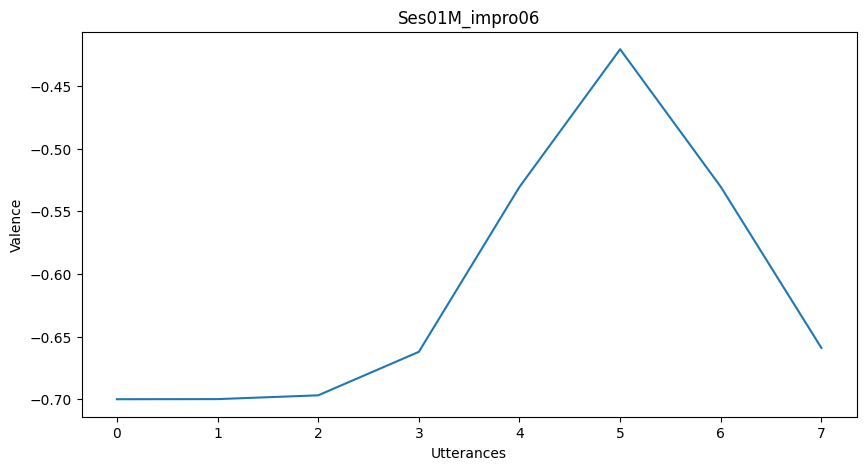

Positive Trend


In [ ]:
# WAVLM-LARGE AUDIO-ONLY EMOTION RECOGNITION
# IEMOCAP 4-CLASS (ang, hap, sad, neu)
# WAVLM-LARGE + MLP


import os
import re
import glob
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d

import torch
import torch.nn as nn

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, classification_report
from sklearn.utils.class_weight import compute_class_weight

from torch.utils.data import TensorDataset, DataLoader, WeightedRandomSampler
from transformers import Wav2Vec2FeatureExtractor, WavLMModel

# DEVICE
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# LOAD WAVLM-LARGE
feature_extractor = Wav2Vec2FeatureExtractor.from_pretrained(
    "microsoft/wavlm-large"
)

wavlm = WavLMModel.from_pretrained(
    "microsoft/wavlm-large"
).to(device)

wavlm.eval()

print("WavLM-large loaded successfully")

# DATA PATH
DATA_PATH = "/content/IEMOCAP_full_release"

valid_emotions = ["ang", "hap", "sad", "neu", "exc"]

wav_paths = []
labels = []

# LOAD DATA
for session in range(1, 6):

    session_path = os.path.join(DATA_PATH, f"Session{session}")

    wav_files = glob.glob(
        os.path.join(session_path, "**/*.wav"),
        recursive=True
    )

    for wav_file in wav_files:

        file_id = os.path.basename(wav_file).replace(".wav", "")
        parts = file_id.split("_")

        if "impro" in file_id:
            ann_name = "_".join(parts[:2]) + ".txt"
        else:
            ann_name = "_".join(parts[:3]) + ".txt"

        ann_path = os.path.join(
            session_path,
            "dialog",
            "EmoEvaluation",
            ann_name
        )

        if not os.path.exists(ann_path):
            continue

        emotion = None

        with open(ann_path, "r", encoding="utf-8", errors="ignore") as f:
            for line in f:
                if file_id in line:
                    split_line = line.strip().split()
                    if len(split_line) >= 5:
                        emotion = split_line[4]
                    break

        if emotion not in valid_emotions:
            continue

        if emotion == "exc":
            emotion = "hap"

        wav_paths.append(wav_file)
        labels.append(emotion)

print("Total samples:", len(wav_paths))

# WAVLM FEATURE EXTRACTION
def extract_wavlm_features(file_path, max_audio_len=4):

    signal, sr = librosa.load(
        file_path,
        sr=16000,
        duration=max_audio_len
    )

    inputs = feature_extractor(
        signal,
        sampling_rate=16000,
        return_tensors="pt",
        padding=True
    )

    input_values = inputs.input_values.to(device)

    with torch.no_grad():

        outputs = wavlm(input_values)

        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()

# FEATURE EXTRACTION (RUNS ONLY ONCE)
X = []
y = []
paths = []

for i in tqdm(range(len(wav_paths))):

    audio_feat = extract_wavlm_features(wav_paths[i])

    X.append(audio_feat)
    y.append(labels[i])
    paths.append(wav_paths[i])

    if i % 100 == 0:
        print(f"Processed {i}/{len(wav_paths)}")

X = np.array(X)
y = np.array(y)

print("Feature shape:", X.shape)

# LABEL ENCODING
le = LabelEncoder()
y = le.fit_transform(y)

# TRAIN TEST SPLIT
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X,
    y,
    paths,
    test_size=0.2,
    stratify=y,
    random_state=42
)

# NORMALIZATION
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PCA
pca = PCA(n_components=100)

X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

print("PCA output shape:", X_train.shape)

# IMBALANCE HANDLING
class_counts = np.bincount(y_train)
weights = 1. / class_counts
sample_weights = weights[y_train]

sampler = WeightedRandomSampler(
    sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# CLASS WEIGHTS
cw = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

cw = torch.tensor(
    cw,
    dtype=torch.float32
).to(device)

# FOCAL LOSS
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.ce = nn.CrossEntropyLoss(
            weight=alpha,
            reduction='none'
        )

    def forward(self, logits, targets):
        ce_loss = self.ce(logits, targets)
        pt = torch.exp(-ce_loss)
        loss = ((1 - pt) ** self.gamma) * ce_loss
        return loss.mean()

# MODEL
class EmotionMLP(nn.Module):
    def __init__(self, input_size, num_classes):
        super().__init__()

        self.net = nn.Sequential(

            nn.Linear(input_size, 512),
            nn.ReLU(),
            nn.BatchNorm1d(512),
            nn.Dropout(0.4),

            nn.Linear(512, 256),
            nn.ReLU(),
            nn.BatchNorm1d(256),
            nn.Dropout(0.3),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = EmotionMLP(
    X_train.shape[1],
    len(np.unique(y))
).to(device)

# DATALOADERS
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train, dtype=torch.float32),
        torch.tensor(y_train)
    ),
    batch_size=32,
    sampler=sampler
)

test_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_test, dtype=torch.float32),
        torch.tensor(y_test)
    ),
    batch_size=32
)

# LOSS + OPTIMIZER
criterion = FocalLoss(alpha=cw, gamma=2)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    patience=2,
    factor=0.5
)

# TRAINING
best_loss = float("inf")
patience = 4
counter = 0

EPOCHS = 25

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0

    for xb, yb in train_loader:

        xb = xb.to(device)
        yb = yb.to(device)

        preds = model(xb)

        loss = criterion(preds, yb)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)

    scheduler.step(avg_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS}, "
        f"Loss: {avg_loss:.4f}"
    )

    # early stopping
    if avg_loss < best_loss:
        best_loss = avg_loss
        counter = 0
        torch.save(model.state_dict(), "best_model.pth")
    else:
        counter += 1

    if counter >= patience:
        print("Early stopping")
        break

# LOAD BEST MODEL
model.load_state_dict(torch.load("best_model.pth"))

# EVALUATION
model.eval()

all_preds = []

with torch.no_grad():

    for xb, _ in test_loader:

        xb = xb.to(device)

        preds = torch.argmax(model(xb), dim=1)

        all_preds.extend(preds.cpu().numpy())

print("\nAccuracy:", accuracy_score(y_test, all_preds))

print(
    classification_report(
        y_test,
        all_preds,
        target_names=le.classes_
    )
)

pred_labels = le.inverse_transform(all_preds)

# CONVERSATION GROUPING
records = []

for idx, (path, pred) in enumerate(
    zip(paths_test, pred_labels)
):

    filename = os.path.basename(path).replace(".wav", "")
    parts = filename.split("_")

    conv_id = "_".join(parts[:2])

    match = re.search(r'[MF](\d+)', filename)

    if match:
        utt_id = int(match.group(1))
    else:
        utt_id = idx

    records.append({

        "conversation_id": conv_id,
        "utterance_id": utt_id,
        "emotion_label": pred
    })

df = pd.DataFrame(records)

df = df.sort_values(
    by=["conversation_id", "utterance_id"]
)

# EMOTION TREND ANALYSIS
VAD_MAP = {

    "hap": (0.8, 0.7, 0.6),
    "sad": (-0.7, 0.3, 0.4),
    "ang": (-0.6, 0.8, 0.7),
    "neu": (0.0, 0.5, 0.5)
}

os.makedirs("plots", exist_ok=True)

for cid, grp in df.groupby("conversation_id"):

    emotions = grp["emotion_label"].tolist()

    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:, 0], 1)
    aro = gaussian_filter1d(vad[:, 1], 1)
    dom = gaussian_filter1d(vad[:, 2], 1)

    plt.figure(figsize=(10,5))

    plt.plot(val, label="Valence")
    plt.plot(aro, label="Arousal")
    plt.plot(dom, label="Dominance")

    plt.legend()
    plt.title(cid)

    plt.xlabel("Utterances")
    plt.ylabel("Emotion Intensity")

    plt.savefig(f"plots/{cid}.png")
    plt.close()

print("Plots saved in plots/ folder")

# USER QUERY
print("\nAvailable Conversation IDs:")
print(df["conversation_id"].unique()[:20])

cid = input("\nEnter conversation ID: ")

subset = df[df["conversation_id"] == cid]

if len(subset) > 0:

    emotions = subset["emotion_label"].tolist()

    vad = np.array([VAD_MAP[e] for e in emotions])

    val = gaussian_filter1d(vad[:, 0], 1)

    plt.figure(figsize=(10,5))

    plt.plot(val)

    plt.title(cid)

    plt.xlabel("Utterances")
    plt.ylabel("Valence")

    plt.show()

    trend = val[-1] - val[0]

    if trend > 0:
        print("Positive Trend")
    elif trend < 0:
        print("Negative Trend")
    else:
        print("Stable Trend")

else:
    print("Conversation ID not found")